<a href="https://colab.research.google.com/github/JanudaG/Flight-Delay-Prediction-and-Early-Warning-System/blob/main/Flight_Delay_ML_Progress_17Nov2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import kagglehub

path = kagglehub.dataset_download("kesinisoujanya/airline-flight-delay-dataset-100k-records")
print(path)
import os; print(os.listdir(path))

Using Colab cache for faster access to the 'airline-flight-delay-dataset-100k-records' dataset.
/kaggle/input/airline-flight-delay-dataset-100k-records
['flights.csv']


In [ ]:
df = pd.read_csv(path + "/flights.csv")
print(df.shape)
df.head()

(1048575, 28)


,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,...,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,Unnamed: 27
0,01-01-2018,UA,2429,EWR,DEN,1517,1512.0,-5.0,15.0,1527.0,...,268.0,250.0,225.0,1605,NaN,NaN,NaN,NaN,NaN,NaN
1,01-01-2018,UA,2427,LAS,SFO,1115,1107.0,-8.0,11.0,1118.0,...,99.0,83.0,65.0,414,NaN,NaN,NaN,NaN,NaN,NaN
2,01-01-2018,UA,2426,SNA,DEN,1335,1330.0,-5.0,15.0,1345.0,...,134.0,126.0,106.0,846,NaN,NaN,NaN,NaN,NaN,NaN
3,01-01-2018,UA,2425,RSW,ORD,1546,1552.0,6.0,19.0,1611.0,...,190.0,182.0,157.0,1120,NaN,NaN,NaN,NaN,NaN,NaN
4,01-01-2018,UA,2424,ORD,ALB,630,650.0,20.0,13.0,703.0,...,112.0,106.0,83.0,723,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Total rows: 1048575
Duplicate rows: 0
Duplicate percentage: 0.0 %


In [ ]:
# Display duplicate records
df[df.duplicated(keep=False)].head(10)

,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,...,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,Unnamed: 27


In [ ]:
# Check missing values
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage.round(2)
})

missing_table = missing_table.sort_values(
    by='Missing Percentage (%)',
    ascending=False
)

display(missing_table)

,Missing Count,Missing Percentage (%)
Unnamed: 27,1048575,100.00
CANCELLATION_CODE,1022662,97.53
NAS_DELAY,859057,81.93
LATE_AIRCRAFT_DELAY,859057,81.93
SECURITY_DELAY,859057,81.93
WEATHER_DELAY,859057,81.93
CARRIER_DELAY,859057,81.93
ARR_DELAY,28892,2.76
ACTUAL_ELAPSED_TIME,28490,2.72
AIR_TIME,28490,2.72


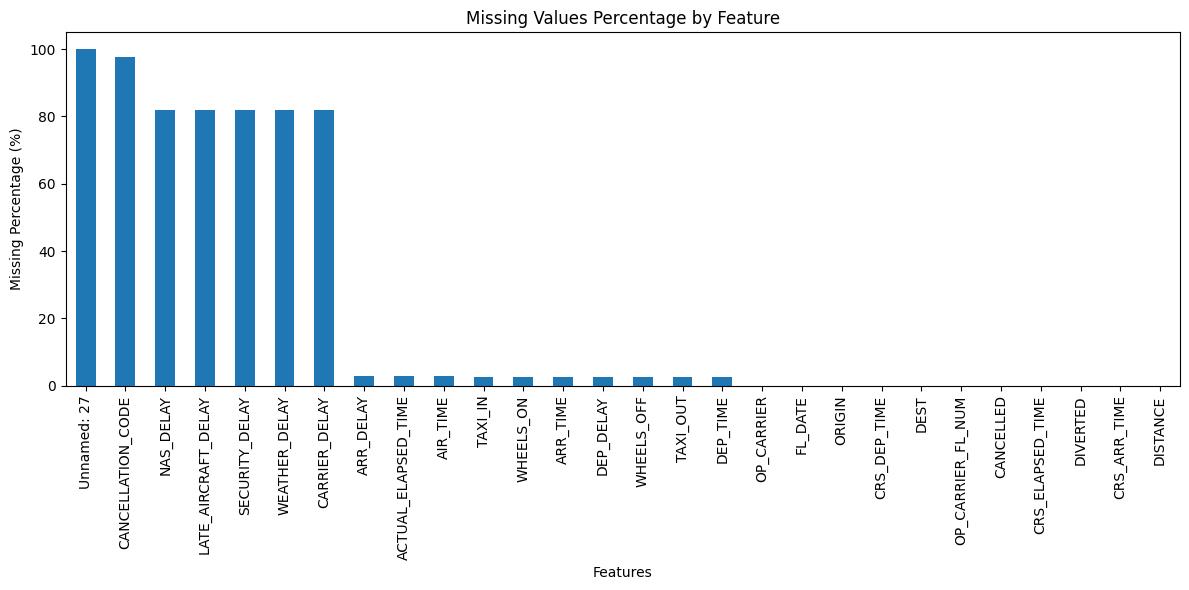

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

missing_table['Missing Percentage (%)'].plot(kind='bar')

plt.title('Missing Values Percentage by Feature')
plt.xlabel('Features')
plt.ylabel('Missing Percentage (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 28 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   FL_DATE              1048575 non-null  object 
 1   OP_CARRIER           1048575 non-null  object 
 2   OP_CARRIER_FL_NUM    1048575 non-null  int64  
 3   ORIGIN               1048575 non-null  object 
 4   DEST                 1048575 non-null  object 
 5   CRS_DEP_TIME         1048575 non-null  int64  
 6   DEP_TIME             1023321 non-null  float64
 7   DEP_DELAY            1022413 non-null  float64
 8   TAXI_OUT             1022842 non-null  float64
 9   WHEELS_OFF           1022842 non-null  float64
 10  WHEELS_ON            1021967 non-null  float64
 11  TAXI_IN              1021967 non-null  float64
 12  CRS_ARR_TIME         1048575 non-null  int64  
 13  ARR_TIME             1021967 non-null  float64
 14  ARR_DELAY            1019683 non-null  float64
 15

In [ ]:
# Check numerical statistics
df.describe()

,OP_CARRIER_FL_NUM,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,...,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,Unnamed: 27
count,1.048575e+06,1.048575e+06,1.023321e+06,1.022413e+06,1.022842e+06,1.022842e+06,1.021967e+06,1.021967e+06,1.048575e+06,1.021967e+06,...,1.048568e+06,1.020085e+06,1.020085e+06,1.048575e+06,189518.000000,189518.000000,189518.000000,189518.000000,189518.000000,0.0
mean,2.575426e+03,1.326853e+03,1.333720e+03,9.698910e+00,1.788974e+01,1.359791e+03,1.479243e+03,7.478019e+00,1.495897e+03,1.484716e+03,...,1.430301e+02,1.372640e+02,1.119085e+02,7.928870e+02,20.297159,4.362894,14.768708,0.091490,25.371500,NaN
std,1.880291e+03,4.849445e+02,4.955356e+02,4.601377e+01,1.056946e+01,4.954444e+02,5.181678e+02,5.801375e+00,5.093058e+02,5.219947e+02,...,7.381580e+01,7.316385e+01,7.134835e+01,5.900519e+02,63.416708,34.601651,32.965929,2.914777,50.378662,NaN
min,1.000000e+00,1.000000e+00,1.000000e+00,-5.100000e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,-6.000000e+01,1.600000e+01,8.000000e+00,3.100000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,9.320000e+02,9.150000e+02,9.220000e+02,-6.000000e+00,1.100000e+01,9.390000e+02,1.059000e+03,4.000000e+00,1.110000e+03,1.104000e+03,...,9.000000e+01,8.400000e+01,6.000000e+01,3.580000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
50%,2.037000e+03,1.320000e+03,1.329000e+03,-2.000000e+00,1.500000e+01,1.343000e+03,1.514000e+03,6.000000e+00,1.522000e+03,1.518000e+03,...,1.250000e+02,1.190000e+02,9.300000e+01,6.320000e+02,0.000000,0.000000,2.000000,0.000000,2.000000,NaN
75%,4.043000e+03,1.730000e+03,1.739000e+03,6.000000e+00,2.100000e+01,1.754000e+03,1.912000e+03,9.000000e+00,1.919000e+03,1.918000e+03,...,1.740000e+02,1.680000e+02,1.420000e+02,1.028000e+03,17.000000,0.000000,20.000000,0.000000,31.000000,NaN
max,7.439000e+03,2.359000e+03,2.400000e+03,2.482000e+03,1.780000e+02,2.400000e+03,2.400000e+03,2.580000e+02,2.400000e+03,2.400000e+03,...,7.040000e+02,7.390000e+02,6.960000e+02,4.983000e+03,2007.000000,2475.000000,1515.000000,593.000000,2454.000000,NaN


In [ ]:
# Check cancellation and diversion counts
print("Cancelled flights:")
print(df["CANCELLED"].value_counts(dropna=False))

print("\nDiverted flights:")
print(df["DIVERTED"].value_counts(dropna=False))

Cancelled flights:
CANCELLED
0    1022662
1      25913
Name: count, dtype: int64

Diverted flights:
DIVERTED
0    1045998
1       2577
Name: count, dtype: int64


In [ ]:
# Missing ARR_DELAY among cancelled and diverted flights
pd.crosstab(
    [df["CANCELLED"], df["DIVERTED"]],
    df["ARR_DELAY"].isna(),
    rownames=["Cancelled", "Diverted"],
    colnames=["ARR_DELAY Missing"]
)

ARR_DELAY Missing     False  True 
Cancelled Diverted                
0         0         1019683    402
          1               0   2577
1         0               0  25913

In [ ]:
print(df["Unnamed: 27"].isnull().sum())

1048575


In [ ]:
df = df.drop(columns=["Unnamed: 27"])

print("Updated dataset shape:", df.shape)

Updated dataset shape: (1048575, 27)


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working shape:", df_clean.shape)

Original shape: (1048575, 27)
Working shape: (1048575, 27)


In [ ]:
# Remove completely empty column
df_clean = df_clean.drop(
    columns=["Unnamed: 27"],
    errors="ignore"
)

print("Updated shape:", df_clean.shape)

Updated shape: (1048575, 27)


In [ ]:
# Count duplicate records
duplicates = df_clean.duplicated().sum()

print("Total duplicate rows:", duplicates)
print("Duplicate percentage:",
      round(duplicates / len(df_clean) * 100, 2))

Total duplicate rows: 0
Duplicate percentage: 0.0


In [ ]:
display(df_clean[df_clean.duplicated(keep=False)].head(10))

,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,...,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY


In [ ]:
# Departure delay dataset
df_dep = df_clean.copy()

# Arrival delay dataset
df_arr = df_clean.copy()

print("Departure dataset:", df_dep.shape)
print("Arrival dataset:", df_arr.shape)

Departure dataset: (1048575, 27)
Arrival dataset: (1048575, 27)


In [ ]:
# Remove rows without known departure delay
df_dep = df_dep.dropna(subset=["DEP_DELAY"]).copy()

print("Departure records:", len(df_dep))

Departure records: 1022413


In [ ]:
# Remove rows without known arrival delay
df_arr = df_arr.dropna(subset=["ARR_DELAY"]).copy()

print("Arrival records:", len(df_arr))

Arrival records: 1019683


In [ ]:
# 1 = delayed 15 minutes or more
# 0 = delayed less than 15 minutes

df_dep["DEP_DELAY_TARGET"] = (
    df_dep["DEP_DELAY"] >= 15
).astype(int)

print(df_dep["DEP_DELAY_TARGET"].value_counts())

DEP_DELAY_TARGET
0    835411
1    187002
Name: count, dtype: int64


In [ ]:
df_arr["ARR_DELAY_TARGET"] = (
    df_arr["ARR_DELAY"] >= 15
).astype(int)

print(df_arr["ARR_DELAY_TARGET"].value_counts())

ARR_DELAY_TARGET
0    830165
1    189518
Name: count, dtype: int64


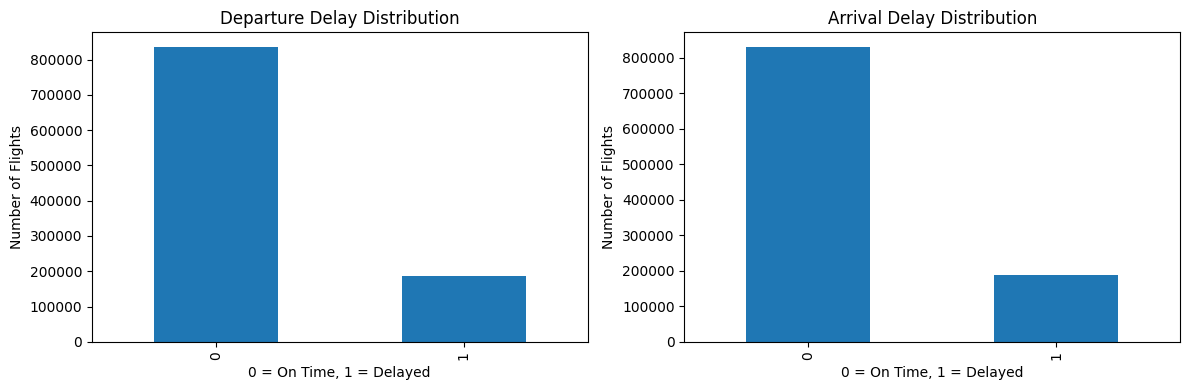

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_dep["DEP_DELAY_TARGET"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Departure Delay Distribution"
)

df_arr["ARR_DELAY_TARGET"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Arrival Delay Distribution"
)

axes[0].set_xlabel("0 = On Time, 1 = Delayed")
axes[1].set_xlabel("0 = On Time, 1 = Delayed")

axes[0].set_ylabel("Number of Flights")
axes[1].set_ylabel("Number of Flights")

plt.tight_layout()
plt.show()

In [ ]:
# 10 minutes threshold
df_dep["DEP_DELAY_TARGET_10"] = (df_dep["DEP_DELAY"] >= 10).astype(int)
df_arr["ARR_DELAY_TARGET_10"] = (df_arr["ARR_DELAY"] >= 10).astype(int)

print("Departure 10-min target")
print(df_dep["DEP_DELAY_TARGET_10"].value_counts())

print("\nArrival 10-min target")
print(df_arr["ARR_DELAY_TARGET_10"].value_counts())

Departure 10-min target
DEP_DELAY_TARGET_10
0    797723
1    224690
Name: count, dtype: int64

Arrival 10-min target
ARR_DELAY_TARGET_10
0    790188
1    229495
Name: count, dtype: int64


In [ ]:
# 20 minutes threshold
df_dep["DEP_DELAY_TARGET_20"] = (df_dep["DEP_DELAY"] >= 20).astype(int)
df_arr["ARR_DELAY_TARGET_20"] = (df_arr["ARR_DELAY"] >= 20).astype(int)

print("Departure 20-min target")
print(df_dep["DEP_DELAY_TARGET_20"].value_counts())

print("\nArrival 20-min target")
print(df_arr["ARR_DELAY_TARGET_20"].value_counts())

Departure 20-min target
DEP_DELAY_TARGET_20
0    863359
1    159054
Name: count, dtype: int64

Arrival 20-min target
ARR_DELAY_TARGET_20
0    859736
1    159947
Name: count, dtype: int64


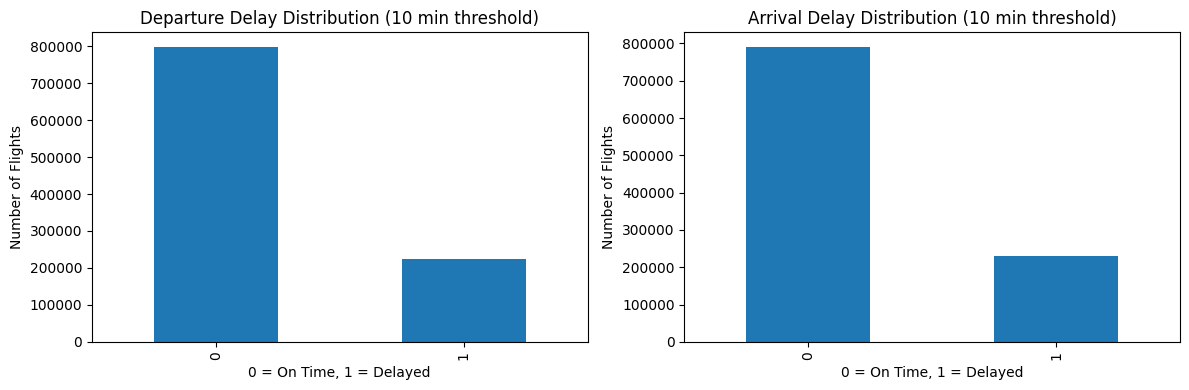

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_dep["DEP_DELAY_TARGET_10"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Departure Delay Distribution (10 min threshold)"
)

df_arr["ARR_DELAY_TARGET_10"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Arrival Delay Distribution (10 min threshold)"
)

axes[0].set_xlabel("0 = On Time, 1 = Delayed")
axes[1].set_xlabel("0 = On Time, 1 = Delayed")

axes[0].set_ylabel("Number of Flights")
axes[1].set_ylabel("Number of Flights")

plt.tight_layout()
plt.show()

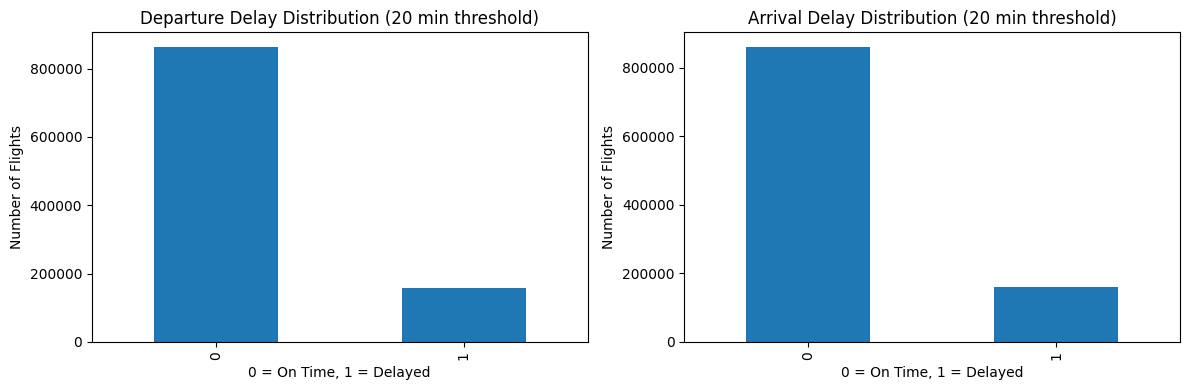

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_dep["DEP_DELAY_TARGET_20"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Departure Delay Distribution (20 min threshold)"
)

df_arr["ARR_DELAY_TARGET_20"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Arrival Delay Distribution (20 min threshold)"
)

axes[0].set_xlabel("0 = On Time, 1 = Delayed")
axes[1].set_xlabel("0 = On Time, 1 = Delayed")

axes[0].set_ylabel("Number of Flights")
axes[1].set_ylabel("Number of Flights")

plt.tight_layout()
plt.show()

In [ ]:
# Count delayed and on-time for each threshold
dep_compare = {
    "10 min": df_dep["DEP_DELAY_TARGET_10"].value_counts().sort_index(),
    "15 min": df_dep["DEP_DELAY_TARGET"].value_counts().sort_index(),
    "20 min": df_dep["DEP_DELAY_TARGET_20"].value_counts().sort_index()
}

arr_compare = {
    "10 min": df_arr["ARR_DELAY_TARGET_10"].value_counts().sort_index(),
    "15 min": df_arr["ARR_DELAY_TARGET"].value_counts().sort_index(),
    "20 min": df_arr["ARR_DELAY_TARGET_20"].value_counts().sort_index()
}

dep_compare_df = pd.DataFrame(dep_compare).T
arr_compare_df = pd.DataFrame(arr_compare).T

dep_compare_df.columns = ["On Time (0)", "Delayed (1)"]
arr_compare_df.columns = ["On Time (0)", "Delayed (1)"]

print("Departure comparison")
display(dep_compare_df)

print("Arrival comparison")
display(arr_compare_df)

Departure comparison


,On Time (0),Delayed (1)
10 min,797723,224690
15 min,835411,187002
20 min,863359,159054


Arrival comparison


,On Time (0),Delayed (1)
10 min,790188,229495
15 min,830165,189518
20 min,859736,159947


In [ ]:
# Departure percentages
dep_percent = dep_compare_df.div(dep_compare_df.sum(axis=1), axis=0) * 100

# Arrival percentages
arr_percent = arr_compare_df.div(arr_compare_df.sum(axis=1), axis=0) * 100

print("Departure percentage comparison")
display(dep_percent.round(2))

print("Arrival percentage comparison")
display(arr_percent.round(2))

Departure percentage comparison


,On Time (0),Delayed (1)
10 min,78.02,21.98
15 min,81.71,18.29
20 min,84.44,15.56


Arrival percentage comparison


,On Time (0),Delayed (1)
10 min,77.49,22.51
15 min,81.41,18.59
20 min,84.31,15.69


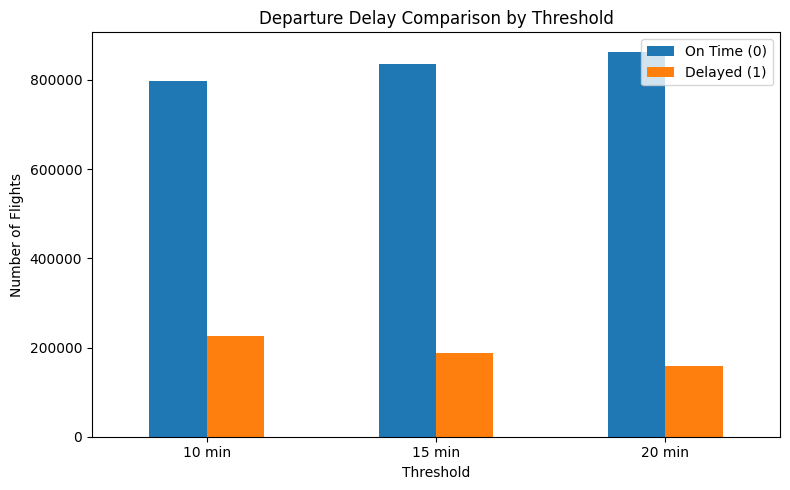

In [ ]:
dep_compare_df.plot(kind="bar", figsize=(8,5))
plt.title("Departure Delay Comparison by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

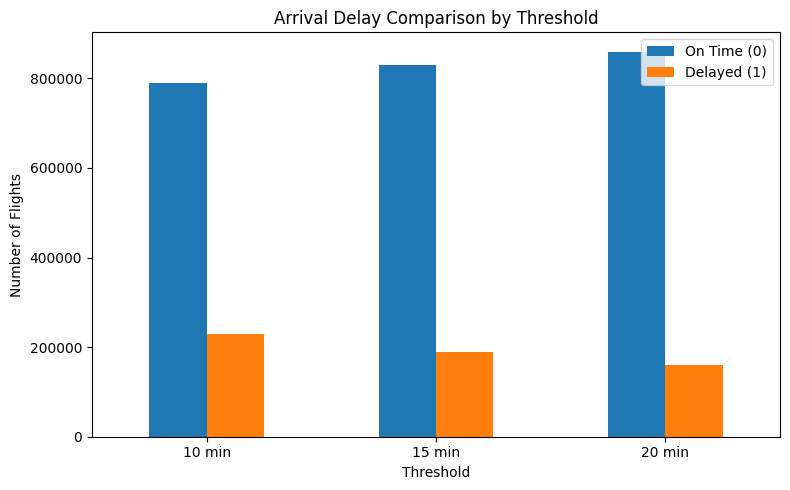

In [ ]:
arr_compare_df.plot(kind="bar", figsize=(8,5))
plt.title("Arrival Delay Comparison by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

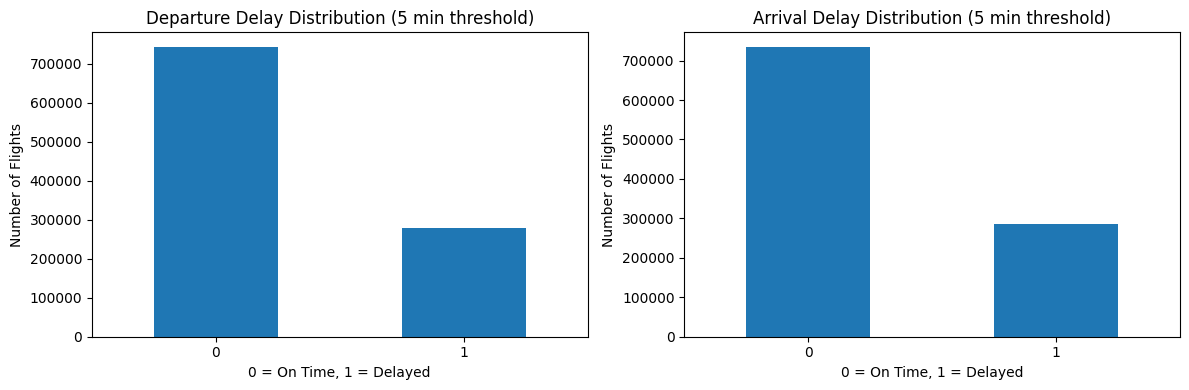

In [ ]:
import matplotlib.pyplot as plt

# Create 5-minute target columns
df_dep["DEP_DELAY_TARGET_5"] = (df_dep["DEP_DELAY"] >= 5).astype(int)
df_arr["ARR_DELAY_TARGET_5"] = (df_arr["ARR_DELAY"] >= 5).astype(int)

# Plot graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_dep["DEP_DELAY_TARGET_5"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Departure Delay Distribution (5 min threshold)"
)

df_arr["ARR_DELAY_TARGET_5"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Arrival Delay Distribution (5 min threshold)"
)

for ax in axes:
    ax.set_xlabel("0 = On Time, 1 = Delayed")
    ax.set_ylabel("Number of Flights")
    ax.set_xticklabels(["0", "1"], rotation=0)

plt.tight_layout()
plt.show()

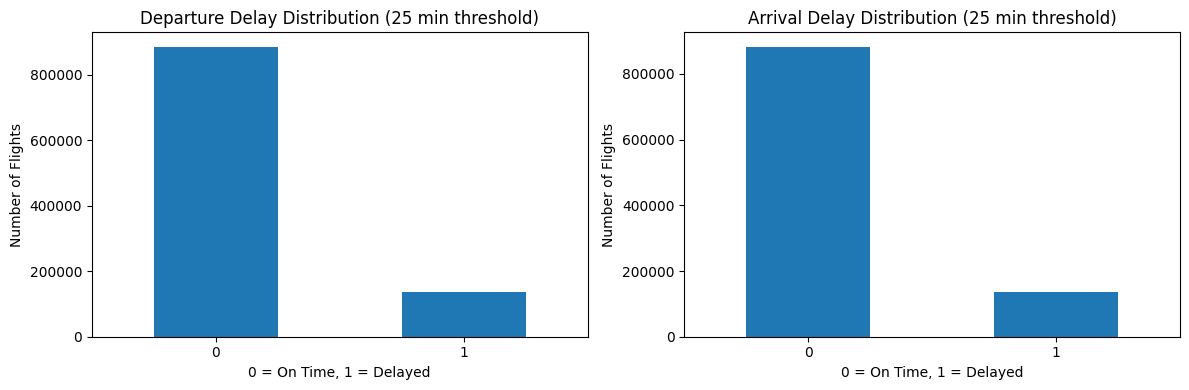

In [ ]:
# Create 25-minute target columns
df_dep["DEP_DELAY_TARGET_25"] = (df_dep["DEP_DELAY"] >= 25).astype(int)
df_arr["ARR_DELAY_TARGET_25"] = (df_arr["ARR_DELAY"] >= 25).astype(int)

# Plot graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_dep["DEP_DELAY_TARGET_25"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Departure Delay Distribution (25 min threshold)"
)

df_arr["ARR_DELAY_TARGET_25"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="Arrival Delay Distribution (25 min threshold)"
)

for ax in axes:
    ax.set_xlabel("0 = On Time, 1 = Delayed")
    ax.set_ylabel("Number of Flights")
    ax.set_xticklabels(["0", "1"], rotation=0)

plt.tight_layout()
plt.show()

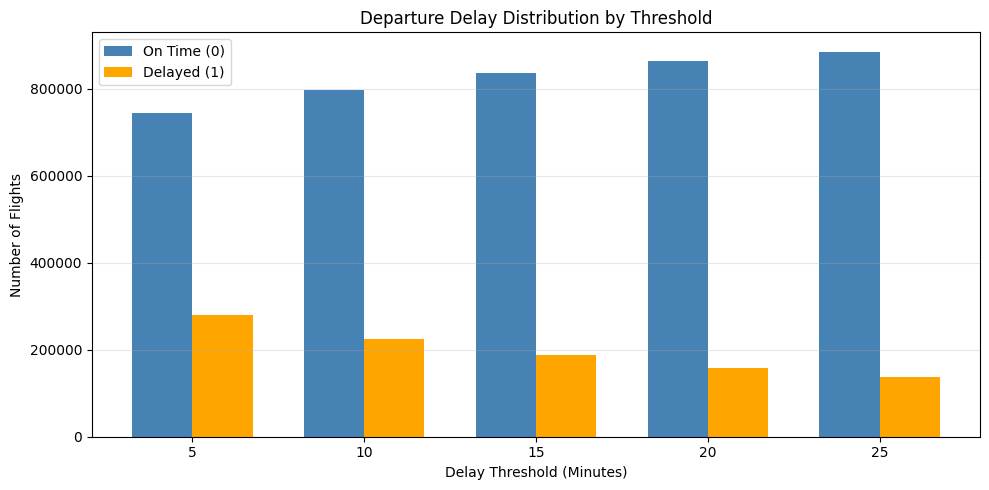

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [5, 10, 15, 20, 25]

on_time = []
delayed = []

for t in thresholds:
    on_time.append((df_dep["DEP_DELAY"] < t).sum())
    delayed.append((df_dep["DEP_DELAY"] >= t).sum())

x = np.arange(len(thresholds))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, on_time, width,
        label="On Time (0)", color="steelblue")

plt.bar(x + width/2, delayed, width,
        label="Delayed (1)", color="orange")

plt.xlabel("Delay Threshold (Minutes)")
plt.ylabel("Number of Flights")
plt.title("Departure Delay Distribution by Threshold")
plt.xticks(x, thresholds)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

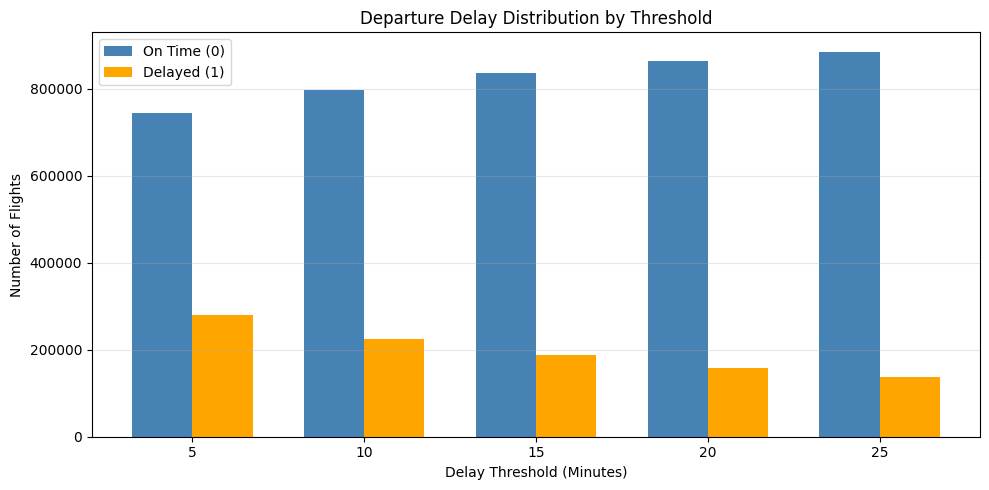

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [5, 10, 15, 20, 25]

on_time = []
delayed = []

for t in thresholds:
    on_time.append((df_dep["DEP_DELAY"] < t).sum())
    delayed.append((df_dep["DEP_DELAY"] >= t).sum())

x = np.arange(len(thresholds))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, on_time, width,
        label="On Time (0)", color="steelblue")

plt.bar(x + width/2, delayed, width,
        label="Delayed (1)", color="orange")

plt.xlabel("Delay Threshold (Minutes)")
plt.ylabel("Number of Flights")
plt.title("Departure Delay Distribution by Threshold")
plt.xticks(x, thresholds)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Make sure departure delay values are available
df_dep = df_dep.dropna(subset=["DEP_DELAY"]).copy()

# Create multi-class departure target
df_dep["DEP_DELAY_CLASS"] = pd.cut(
    df_dep["DEP_DELAY"],
    bins=[-np.inf, 5, 15, 20, np.inf],
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

# Display class counts
print("Departure Delay Classes:")
print(df_dep["DEP_DELAY_CLASS"].value_counts().sort_index())

Departure Delay Classes:
DEP_DELAY_CLASS
0    743553
1     91858
2     27948
3    159054
Name: count, dtype: int64


In [ ]:
# Make sure arrival delay values are available
df_arr = df_arr.dropna(subset=["ARR_DELAY"]).copy()

# Create multi-class arrival target
df_arr["ARR_DELAY_CLASS"] = pd.cut(
    df_arr["ARR_DELAY"],
    bins=[-np.inf, 5, 15, 20, np.inf],
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

# Display class counts
print("Arrival Delay Classes:")
print(df_arr["ARR_DELAY_CLASS"].value_counts().sort_index())

Arrival Delay Classes:
ARR_DELAY_CLASS
0    734782
1     95383
2     29571
3    159947
Name: count, dtype: int64


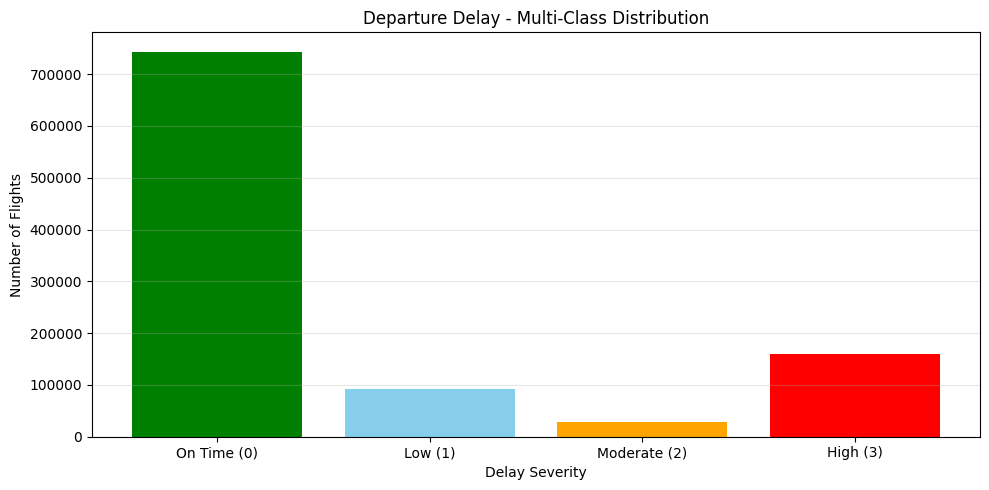

In [ ]:
import matplotlib.pyplot as plt

dep_counts = df_dep["DEP_DELAY_CLASS"].value_counts().reindex(
    [0, 1, 2, 3], fill_value=0
)

labels = ["On Time (0)", "Low (1)", "Moderate (2)", "High (3)"]

plt.figure(figsize=(10, 5))

plt.bar(
    labels,
    dep_counts.values,
    color=["green", "skyblue", "orange", "red"]
)

plt.title("Departure Delay - Multi-Class Distribution")
plt.xlabel("Delay Severity")
plt.ylabel("Number of Flights")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

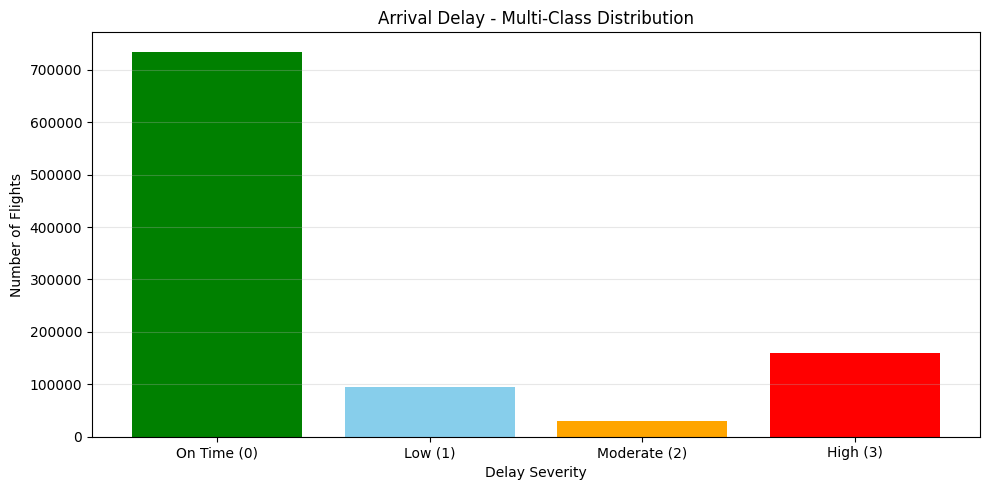

In [ ]:
arr_counts = df_arr["ARR_DELAY_CLASS"].value_counts().reindex(
    [0, 1, 2, 3], fill_value=0
)

labels = ["On Time (0)", "Low (1)", "Moderate (2)", "High (3)"]

plt.figure(figsize=(10, 5))

plt.bar(
    labels,
    arr_counts.values,
    color=["green", "skyblue", "orange", "red"]
)

plt.title("Arrival Delay - Multi-Class Distribution")
plt.xlabel("Delay Severity")
plt.ylabel("Number of Flights")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Select numerical features
numerical_cols = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

# Select categorical features
categorical_cols = df_clean.select_dtypes(
    include=['object', 'category', 'string']
).columns

print("Total Features:", df_clean.shape[1])
print("Numerical Features:", len(numerical_cols))
print("Categorical Features:", len(categorical_cols))

print("\nNumerical Feature Names:")
print(numerical_cols.tolist())

print("\nCategorical Feature Names:")
print(categorical_cols.tolist())

Total Features: 27
Numerical Features: 22
Categorical Features: 5

Numerical Feature Names:
['OP_CARRIER_FL_NUM', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']

Categorical Feature Names:
['FL_DATE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'CANCELLATION_CODE']


In [ ]:
import pandas as pd

feature_types = pd.DataFrame({
    "Feature": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Category": [
        "Numerical" if col in numerical_cols
        else "Categorical" if col in categorical_cols
        else "Other"
        for col in df_clean.columns
    ]
})

display(feature_types)

,Feature,Data Type,Category
0,FL_DATE,object,Categorical
1,OP_CARRIER,object,Categorical
2,OP_CARRIER_FL_NUM,int64,Numerical
3,ORIGIN,object,Categorical
4,DEST,object,Categorical
5,CRS_DEP_TIME,int64,Numerical
6,DEP_TIME,float64,Numerical
7,DEP_DELAY,float64,Numerical
8,TAXI_OUT,float64,Numerical
9,WHEELS_OFF,float64,Numerical


Total Numerical Features: 22
['OP_CARRIER_FL_NUM', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']


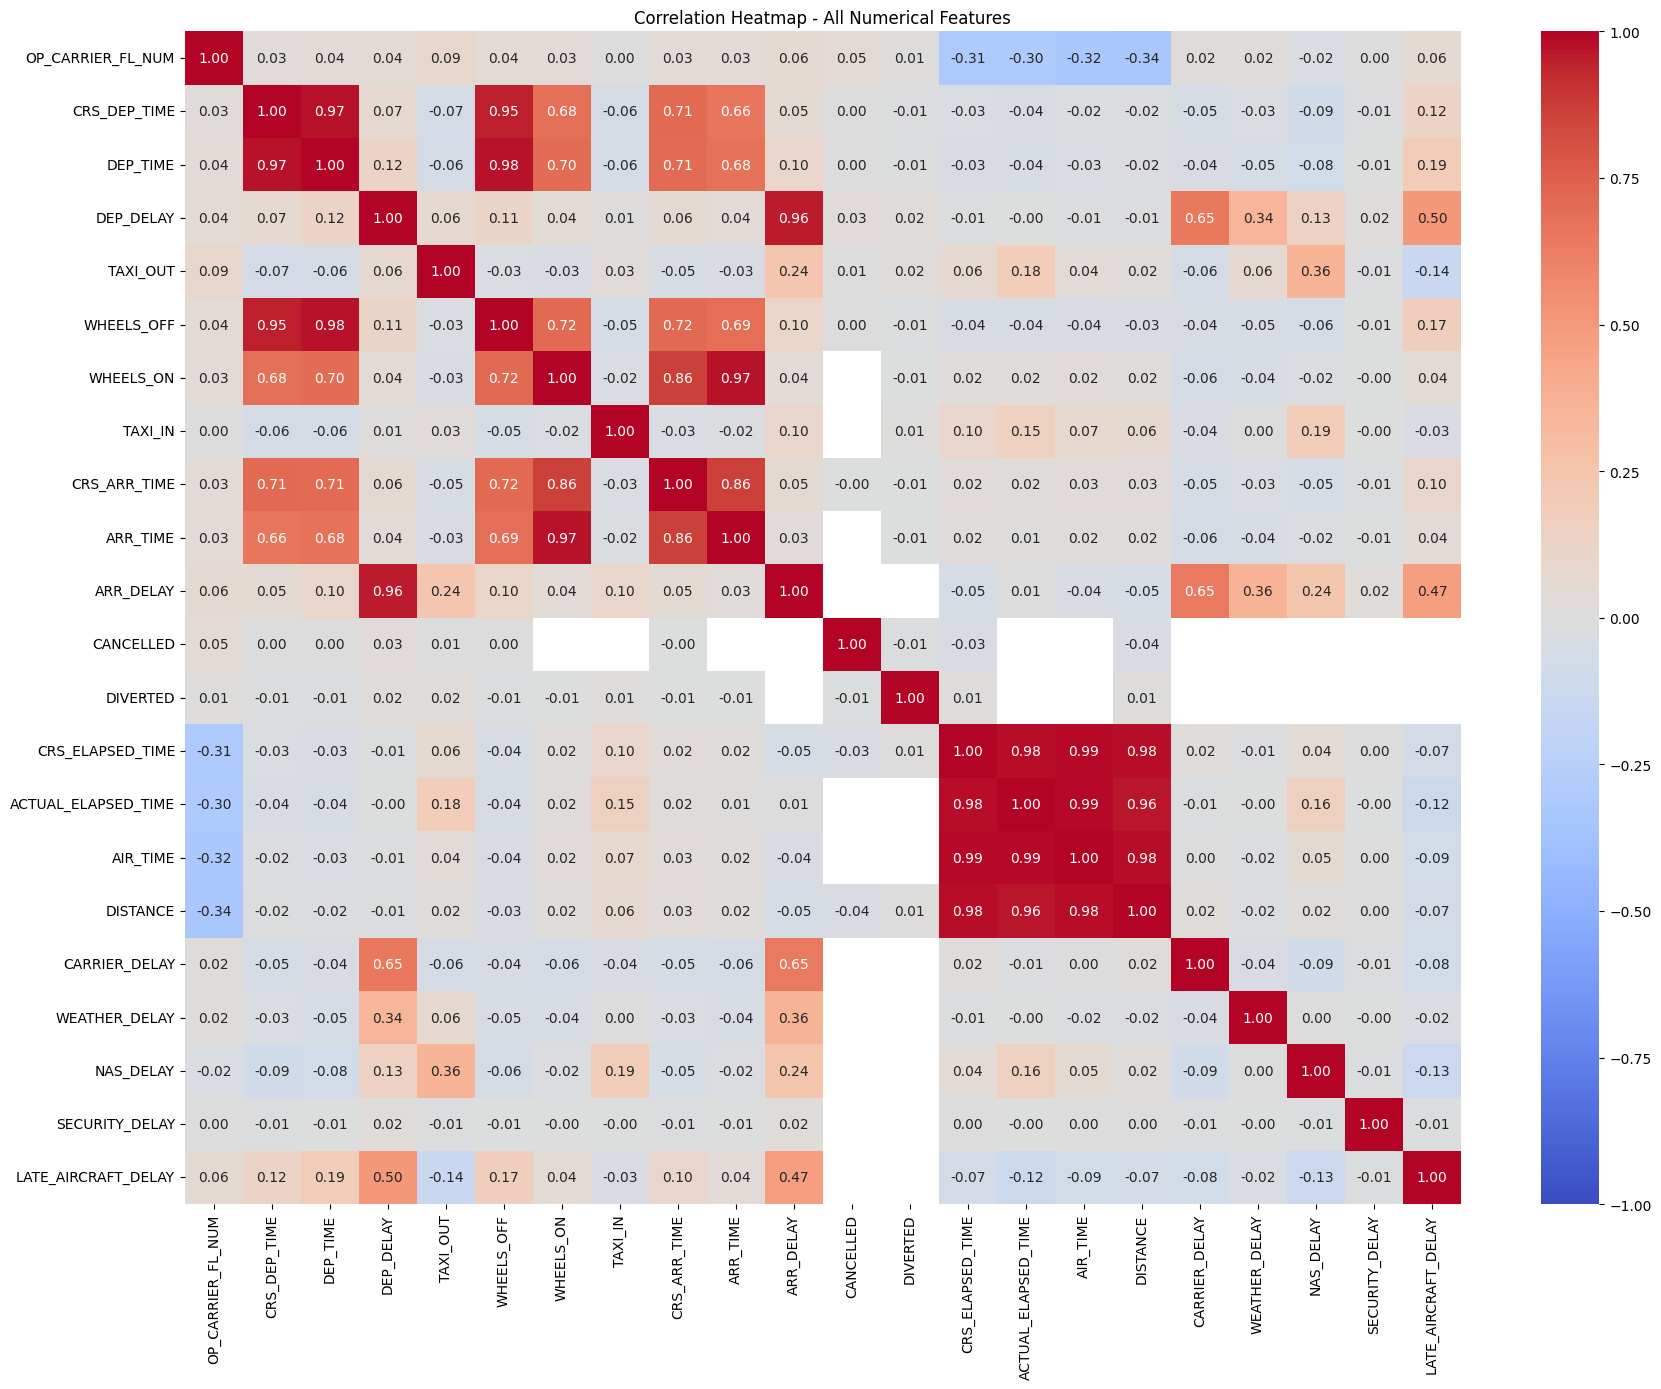

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical features
numerical_df = df_clean.select_dtypes(include="number")

print("Total Numerical Features:", numerical_df.shape[1])
print(numerical_df.columns.tolist())

# Calculate correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - All Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get all original numerical features
numeric_cols = df_clean.select_dtypes(
    include="number"
).columns.tolist()

# Add departure multi-class target
dep_cols = [
    col for col in numeric_cols
    if col != "DEP_DELAY_CLASS"
]

dep_data = df_dep[dep_cols + ["DEP_DELAY_CLASS"]]

# Calculate correlation matrix
dep_corr = dep_data.corr()

# Plot heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    dep_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7}
)

plt.title("Departure Delay - Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Get all original numerical features
numeric_cols = df_clean.select_dtypes(
    include="number"
).columns.tolist()

# Add arrival multi-class target
arr_cols = [
    col for col in numeric_cols
    if col != "ARR_DELAY_CLASS"
]

arr_data = df_arr[arr_cols + ["ARR_DELAY_CLASS"]]

# Calculate correlation matrix
arr_corr = arr_data.corr()

# Plot heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    arr_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7}
)

plt.title("Arrival Delay - Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
print("Cancelled values:")
print(df_arr["CANCELLED"].value_counts())

print("\nDiverted values:")
print(df_arr["DIVERTED"].value_counts())

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical features
arr_numeric = df_arr.select_dtypes(include="number").copy()

# Remove constant columns only from heatmap data
arr_numeric = arr_numeric.loc[:, arr_numeric.nunique() > 1]

# Calculate correlation
arr_corr = arr_numeric.corr()

# Plot heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    arr_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8}
)

plt.title("Arrival Delay - Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:
# Select all numerical features
dep_numeric = df_dep.select_dtypes(include="number").copy()

# Remove constant columns only from heatmap data
dep_numeric = dep_numeric.loc[:, dep_numeric.nunique() > 1]

# Calculate correlation
dep_corr = dep_numeric.corr()

# Plot heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    dep_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8}
)

plt.title("Departure Delay - Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

features = ["DISTANCE", "CRS_ELAPSED_TIME"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, feature in enumerate(features):

    sns.histplot(
        df_dep[feature].dropna(),
        bins=40,
        ax=axes[i, 0],
        color="steelblue"
    )
    axes[i, 0].set_title(f"Departure - {feature} Distribution")

    sns.histplot(
        df_arr[feature].dropna(),
        bins=40,
        ax=axes[i, 1],
        color="orange"
    )
    axes[i, 1].set_title(f"Arrival - {feature} Distribution")

plt.tight_layout()
plt.show()

distribution of numerical features (Computer Reservation System Elapsed Time - CRS_ELAPSED_TIME  [Scheduled Flight Duration])

In [ ]:
features = ["OP_CARRIER", "ORIGIN", "DEST"]

fig, axes = plt.subplots(3, 1, figsize=(12, 13))

for i, feature in enumerate(features):

    counts = df_clean[feature].value_counts().head(10)

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Top 10 - {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Flights")

plt.tight_layout()
plt.show()

categorical distribution

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_dep,
    x="DEP_DELAY_CLASS",
    y="DISTANCE",
    ax=axes[0],
    showfliers=False,
    color="skyblue"
)

axes[0].set_title("Distance vs Departure Delay Category")
axes[0].set_xlabel("Delay Class (0, 1, 2, 3)")

sns.boxplot(
    data=df_arr,
    x="ARR_DELAY_CLASS",
    y="DISTANCE",
    ax=axes[1],
    showfliers=False,
    color="orange"
)

axes[1].set_title("Distance vs Arrival Delay Category")
axes[1].set_xlabel("Delay Class (0, 1, 2, 3)")

plt.tight_layout()
plt.show()

when we are doing EDA process, in there feature relationship we have to choose features as we want.

In [ ]:
import pandas as pd

feature_analysis = pd.DataFrame({
    "Feature": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (df_clean.isnull().mean() * 100).round(2).values,
    "Unique Values": df_clean.nunique().values
})

display(feature_analysis)

In [ ]:
import pandas as pd
import numpy as np

# Create analysis dataset
eda_base = df_clean.drop_duplicates().copy()

# Keep normally operated flights
eda_base = eda_base[
    (eda_base["CANCELLED"] == 0) &
    (eda_base["DIVERTED"] == 0)
].copy()

# Separate datasets
df_dep = eda_base.dropna(subset=["DEP_DELAY"]).copy()
df_arr = eda_base.dropna(subset=["ARR_DELAY"]).copy()

# Multi-class targets
bins = [-np.inf, 5, 15, 20, np.inf]

df_dep["DEP_DELAY_CLASS"] = pd.cut(
    df_dep["DEP_DELAY"],
    bins=bins,
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

df_arr["ARR_DELAY_CLASS"] = pd.cut(
    df_arr["ARR_DELAY"],
    bins=bins,
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

print("Departure dataset:", df_dep.shape)
print("Arrival dataset:", df_arr.shape)

In [ ]:
numeric_features = [
    "DISTANCE",
    "CRS_ELAPSED_TIME"
]

def numerical_relationship(data, target):

    results = []

    for feature in numeric_features:

        # Spearman correlation
        corr = data[feature].corr(
            data[target],
            method="spearman"
        )

        # Median value for each delay class
        medians = data.groupby(target)[feature].median()

        results.append({
            "Feature": feature,
            "Spearman": round(corr, 3),
            "On Time (0)": medians.get(0),
            "Low (1)": medians.get(1),
            "Moderate (2)": medians.get(2),
            "High (3)": medians.get(3)
        })

    return pd.DataFrame(results)


dep_numeric_table = numerical_relationship(
    df_dep,
    "DEP_DELAY_CLASS"
)

display(dep_numeric_table)

Departure table

In [ ]:
arr_numeric_table = numerical_relationship(
    df_arr,
    "ARR_DELAY_CLASS"
)

display(arr_numeric_table)

Arrival table

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import os

# Load original dataset if necessary
if "df" not in globals():
    path = kagglehub.dataset_download(
        "kesinisoujanya/airline-flight-delay-dataset-100k-records"
    )
    df = pd.read_csv(os.path.join(path, "flights.csv"))

# Create cleaned dataset
df_clean = df.drop(
    columns=["Unnamed: 27"],
    errors="ignore"
).drop_duplicates().copy()

# Exclude cancelled and diverted flights
df_clean = df_clean[
    (df_clean["CANCELLED"] == 0) &
    (df_clean["DIVERTED"] == 0)
].copy()

# Separate model datasets
df_dep = df_clean.dropna(subset=["DEP_DELAY"]).copy()
df_arr = df_clean.dropna(subset=["ARR_DELAY"]).copy()

# Create multi-class targets
bins = [-np.inf, 5, 15, 20, np.inf]

df_dep["DEP_DELAY_CLASS"] = pd.cut(
    df_dep["DEP_DELAY"],
    bins=bins,
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

df_arr["ARR_DELAY_CLASS"] = pd.cut(
    df_arr["ARR_DELAY"],
    bins=bins,
    labels=[0, 1, 2, 3],
    right=False
).astype(int)

print("Cleaned dataset:", df_clean.shape)
print("Departure dataset:", df_dep.shape)
print("Arrival dataset:", df_arr.shape)

100%|██████████| 30.1M/30.1M [00:00<00:00, 291MB/s]

Extracting files...


Cleaned dataset: (1020085, 27)
Departure dataset: (1019194, 28)
Arrival dataset: (1019683, 28)


The dataset was cleaned by removing duplicates, cancelled flights, and diverted flights. Separate datasets were prepared for departure and arrival delay prediction. Delay severity targets were created using four classes

In [ ]:
# Select numerical features
numeric_data = df_clean.select_dtypes(include="number")

# Remove constant columns from this analysis
numeric_data = numeric_data.loc[
    :, numeric_data.nunique() > 1
]

# Calculate correlations
corr_matrix = numeric_data.corr()

# Keep only unique feature pairs
upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = upper.stack().reset_index()

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

# Filter strong correlations
strong_corr = correlation_pairs[
    correlation_pairs["Correlation"].abs() >= 0.85
].copy()

strong_corr = strong_corr.sort_values(
    by="Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

display(strong_corr)

Correlation analysis was performed to identify strong linear relationships between numerical features. Highly correlated features may contain similar information. However, correlation alone was not used to remove features.

In [ ]:
feature_summary = pd.DataFrame({
    "Feature": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (
        df_clean.isnull().mean() * 100
    ).round(2).values,
    "Unique Values": df_clean.nunique().values
})

display(feature_summary)

Histograms were used to examine the distributions of flight distance and scheduled flight duration. Both features showed right-skewed distributions, indicating that shorter flights were more common than very long flights.

In [ ]:
numerical_features = [
    "DISTANCE",
    "CRS_ELAPSED_TIME"
]

display(
    df_clean[numerical_features].describe().T
)

print("Skewness:")
print(df_clean[numerical_features].skew())

In [ ]:
categorical_features = [
    "OP_CARRIER",
    "ORIGIN",
    "DEST"
]

for feature in categorical_features:
    print("\nFeature:", feature)
    print("Unique categories:",
          df_clean[feature].nunique())

    display(
        df_clean[feature]
        .value_counts()
        .head(10)
        .to_frame("Flight Count")
    )

In [ ]:
features = ["DISTANCE", "CRS_ELAPSED_TIME"]

print("Departure Delay Relationships:")

display(
    df_dep.groupby("DEP_DELAY_CLASS")[features]
    .median()
)

print("Arrival Delay Relationships:")

display(
    df_arr.groupby("ARR_DELAY_CLASS")[features]
    .median()
)

Numerical features were compared across delay severity classes. The distance distributions showed considerable overlap between the classes. Therefore, distance alone may not be sufficient to distinguish delay severity

In [ ]:
def plot_category_relationship(data, feature, target, title):

    # Top 10 categories
    top_values = data[feature].value_counts().head(10).index

    subset = data[data[feature].isin(top_values)]

    # Percentage of each delay category
    table = pd.crosstab(
        subset[feature],
        subset[target],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=[0, 1, 2, 3],
        fill_value=0
    )

    table.columns = [
        "On Time",
        "Low Delay",
        "Moderate Delay",
        "High Delay"
    ]

    table.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 5),
        color=["green", "skyblue", "orange", "red"]
    )

    plt.title(title)
    plt.xlabel(feature)
    plt.ylabel("Percentage of Flights (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


for feature in ["OP_CARRIER", "ORIGIN", "DEST"]:

    plot_category_relationship(
        df_dep,
        feature,
        "DEP_DELAY_CLASS",
        f"{feature} vs Departure Delay"
    )

    plot_category_relationship(
        df_arr,
        feature,
        "ARR_DELAY_CLASS",
        f"{feature} vs Arrival Delay"
    )

NameError: name 'df_dep' is not defined

Categorical features were compared with delay severity classes using percentage-based stacked bar charts. This analysis helps identify whether delay distributions vary across airlines and airports.

In [ ]:
# Cell 66 - Final Departure Delay Classification Dataset

import pandas as pd
import numpy as np

# Select only normally operated flights
df_model = df_dep[
    (df_dep['CANCELLED'] == 0) &
    (df_dep['DIVERTED'] == 0)
].copy()

# Ensure numerical departure delays
df_model['DEP_DELAY'] = pd.to_numeric(
    df_model['DEP_DELAY'], errors='coerce'
)

df_model = df_model.dropna(subset=['DEP_DELAY'])

# Detect flight date format
formats = ['%d-%m-%Y', '%m-%d-%Y', '%Y-%m-%d']

parsed = [
    pd.to_datetime(
        df_model['FL_DATE'],
        format=fmt,
        errors='coerce'
    )
    for fmt in formats
]

best_idx = max(
    range(len(parsed)),
    key=lambda i: parsed[i].notna().sum()
)

df_model['FL_DATE'] = parsed[best_idx]
print("Detected date format:", formats[best_idx])

df_model = df_model.dropna(subset=['FL_DATE'])

# Sort chronologically
df_model = df_model.sort_values(
    'FL_DATE'
).reset_index(drop=True)

# Create binary classification target
# 0 = On time (departure delay < 15 minutes)
# 1 = Delayed (departure delay >= 15 minutes)

df_model['DELAY'] = (
    df_model['DEP_DELAY'] >= 15
).astype(int)

# Keep delay minutes for optional future analysis
df_model['DELAY_MINUTES'] = (
    df_model['DEP_DELAY'].clip(lower=0)
)

# Select pre-departure input features
preflight_features = [
    'FL_DATE',
    'OP_CARRIER',
    'ORIGIN',
    'DEST',
    'CRS_DEP_TIME',
    'CRS_ARR_TIME',
    'CRS_ELAPSED_TIME',
    'DISTANCE'
]

X_raw = df_model[preflight_features].copy()

# Main classification target
y = df_model['DELAY'].copy()

# Display results
print("Dataset shape:", df_model.shape)
print("Input shape:", X_raw.shape)
print("Target shape:", y.shape)

print("\nDate range:")
print(df_model['FL_DATE'].min())
print(df_model['FL_DATE'].max())

print("\nTarget Class Distribution:")
print(y.value_counts().sort_index())

print("\nTarget Class Percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Detected date format: %d-%m-%Y
Dataset shape: (1019194, 30)
Input shape: (1019194, 8)
Target shape: (1019194,)

Date range:
2018-01-01 00:00:00
2018-02-26 00:00:00

Target Class Distribution:
DELAY
0    833300
1    185894
Name: count, dtype: int64

Target Class Percentages:
DELAY
0    81.76
1    18.24
Name: proportion, dtype: float64


In [ ]:
# Cell 67 - Feature Engineering

# Convert scheduled HHMM times into minutes
def time_to_minutes(series):
    t = pd.to_numeric(series, errors='coerce')
    hours = np.floor(t / 100)
    minutes = t % 100

    valid = (
        (hours >= 0) & (hours < 24) &
        (minutes >= 0) & (minutes < 60)
    ) | (t == 2400)

    result = (hours * 60 + minutes).where(valid)
    return result.mask(t == 2400, 0)


dep_minutes = time_to_minutes(X_raw['CRS_DEP_TIME'])
arr_minutes = time_to_minutes(X_raw['CRS_ARR_TIME'])

# Create feature dataset
X = pd.DataFrame(index=X_raw.index)

# Categorical features
for col in ['OP_CARRIER', 'ORIGIN', 'DEST']:
    X[col] = X_raw[col].fillna('Unknown').astype(str)

# Numerical features
X['CRS_ELAPSED_TIME'] = X_raw['CRS_ELAPSED_TIME']
X['DISTANCE'] = X_raw['DISTANCE']

# Date features
X['MONTH'] = df_model['FL_DATE'].dt.month
X['DAY_OF_WEEK'] = df_model['FL_DATE'].dt.dayofweek
X['IS_WEEKEND'] = X['DAY_OF_WEEK'].isin([5, 6]).astype(int)

# Scheduled departure time features
X['DEP_HOUR'] = np.floor(dep_minutes / 60)
X['DEP_SIN'] = np.sin(2 * np.pi * dep_minutes / 1440)
X['DEP_COS'] = np.cos(2 * np.pi * dep_minutes / 1440)

# Scheduled arrival time features
X['ARR_HOUR'] = np.floor(arr_minutes / 60)
X['ARR_SIN'] = np.sin(2 * np.pi * arr_minutes / 1440)
X['ARR_COS'] = np.cos(2 * np.pi * arr_minutes / 1440)

# Route feature
X['ROUTE'] = X['ORIGIN'] + '-' + X['DEST']

# Verify features
print("Final feature dataset shape:", X.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

display(X.head())

Final feature dataset shape: (1019194, 15)

Feature names:
['OP_CARRIER', 'ORIGIN', 'DEST', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'IS_WEEKEND', 'DEP_HOUR', 'DEP_SIN', 'DEP_COS', 'ARR_HOUR', 'ARR_SIN', 'ARR_COS', 'ROUTE']

Missing values:
OP_CARRIER          0
ORIGIN              0
DEST                0
CRS_ELAPSED_TIME    0
DISTANCE            0
MONTH               0
DAY_OF_WEEK         0
IS_WEEKEND          0
DEP_HOUR            0
DEP_SIN             0
DEP_COS             0
ARR_HOUR            0
ARR_SIN             0
ARR_COS             0
ROUTE               0
dtype: int64


,OP_CARRIER,ORIGIN,DEST,CRS_ELAPSED_TIME,DISTANCE,MONTH,DAY_OF_WEEK,IS_WEEKEND,DEP_HOUR,DEP_SIN,DEP_COS,ARR_HOUR,ARR_SIN,ARR_COS,ROUTE
0,UA,EWR,DEN,268.0,1605,1,0,0,15.0,-0.757565,-6.527598e-01,17.0,-0.997859,-0.065403,EWR-DEN
1,WN,SJU,MCO,190.0,1189,1,0,0,11.0,0.237686,-9.713421e-01,13.0,-0.321439,-0.946930,SJU-MCO
2,WN,SJU,MCO,190.0,1189,1,0,0,18.0,-1.000000,-1.836970e-16,20.0,-0.843391,0.537300,SJU-MCO
3,WN,SJU,MCO,190.0,1189,1,0,0,21.0,-0.642788,7.660444e-01,23.0,-0.130526,0.991445,SJU-MCO
4,WN,SJU,MCO,190.0,1189,1,0,0,6.0,1.000000,6.123234e-17,8.0,0.843391,-0.537300,SJU-MCO


### Observation — Final Departure Delay Dataset Preparation

The final dataset contains **1,019,194 flight records** with 8 pre-flight input features and one numerical target variable, `DELAY_MINUTES`.

The dataset covers flight records from **January 1, 2018, to February 26, 2018**.

The target variable was created from `DEP_DELAY`, with negative delay values converted to zero to represent flights departing early or on time.

**Key observations:**

- The average departure delay is approximately **13.01 minutes**.
- The median departure delay is **0 minutes**.
- The 75th percentile is **6 minutes**, indicating that most flights experience relatively small delays.
- The maximum recorded delay is **2,482 minutes**, indicating the presence of extreme delays.
- The delay distribution is strongly right-skewed, with many zero-delay records and a small number of very large delays.

**Conclusion:**

The dataset is prepared for departure delay regression modeling. Only scheduled flight information will be used as input features to avoid data leakage. The numerical target `DELAY_MINUTES` will be used to estimate departure delay in minutes.

The large number of zero-delay records and extreme delay values should be considered during model training and evaluation.

In [ ]:

# Check engineered features

print("Total features:", X.shape[1])

print("\nFeature names:")
for col in X.columns:
    print(col)

print("\nMissing values:")
print(X.isnull().sum())

display(X.head())


In [ ]:

# Cell 67A - Detailed Feature Engineering Summary

import pandas as pd

# 1. Original Features
original_features = [
    'FL_DATE',
    'OP_CARRIER',
    'ORIGIN',
    'DEST',
    'CRS_DEP_TIME',
    'CRS_ARR_TIME',
    'CRS_ELAPSED_TIME',
    'DISTANCE'
]

# 2. Removed Original Features
removed_features = [
    col for col in original_features
    if col not in X.columns
]

# 3. Retained Original Features
retained_features = [
    col for col in original_features
    if col in X.columns
]

# 4. Newly Engineered Features
engineered_features = [
    col for col in X.columns
    if col not in original_features
]

# Display separate feature groups
print("1. ORIGINAL FEATURES:", len(original_features))
print(original_features)

print("\n2. REMOVED ORIGINAL FEATURES:",
      len(removed_features))
print(removed_features)

print("\n3. RETAINED ORIGINAL FEATURES:",
      len(retained_features))
print(retained_features)

print("\n4. NEW ENGINEERED FEATURES:",
      len(engineered_features))
print(engineered_features)

print("\n5. FINAL FEATURES:", X.shape[1])
print(X.columns.tolist())

# Feature Summary Table
summary = pd.DataFrame({
    'Feature Category': [
        'Original Features',
        'Removed Original Features',
        'Retained Original Features',
        'New Engineered Features',
        'Final Features'
    ],
    'Count': [
        len(original_features),
        len(removed_features),
        len(retained_features),
        len(engineered_features),
        X.shape[1]
    ]
})

print("\nFEATURE ENGINEERING SUMMARY")
display(summary)

# Missing value verification
print("\nMissing Values:")
display(X.isnull().sum().to_frame('Missing Count'))

# Preview final dataset
print("\nFinal Engineered Dataset:")
display(X.head())


In [ ]:

# Cell 67A - Feature Engineering Verification

print("Total features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

print("\nFeature data types:")
print(X.dtypes)

display(X.head())


### Observation — Feature Engineering Verification

Feature Engineering was performed using information available before flight departure. New date, scheduled time, and route features were created.

The resulting dataset was inspected to verify the number of features, data types, and missing values.

These features will be used as inputs for the departure delay regression model, while `DELAY_MINUTES` remains the numerical target variable.

In [ ]:

# Cell 68 - Chronological Data Splitting

dates = df_model['FL_DATE']

unique_dates = (
    dates.drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

n = len(unique_dates)

assert n >= 4, "Not enough dates for splitting"

train_end = unique_dates.iloc[int(n * 0.70)]
val_end = unique_dates.iloc[int(n * 0.85)]

train_mask = dates < train_end

val_mask = (
    (dates >= train_end) &
    (dates < val_end)
)

test_mask = dates >= val_end

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining ends before:", train_end.date())
print("Testing starts:", val_end.date())


Training records: 694043
Validation records: 159534
Testing records: 165617

Training ends before: 2018-02-09
Testing starts: 2018-02-18


Data Preprocessing part

In [ ]:

# Cell 69 - Identify Categorical and Numerical Features

categorical_cols = [
    'OP_CARRIER',
    'ORIGIN',
    'DEST',
    'ROUTE'
]

numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Categorical Features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical Features:", len(numerical_cols))
print(numerical_cols)

print("\nUnique Categories in Training Data:")
print(X_train[categorical_cols].nunique())

print("\nMissing Values in Training Data:")
print(X_train.isnull().sum())


Categorical Features: 4
['OP_CARRIER', 'ORIGIN', 'DEST', 'ROUTE']

Numerical Features: 11
['CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'IS_WEEKEND', 'DEP_HOUR', 'DEP_SIN', 'DEP_COS', 'ARR_HOUR', 'ARR_SIN', 'ARR_COS']

Unique Categories in Training Data:
OP_CARRIER      18
ORIGIN         336
DEST           336
ROUTE         5245
dtype: int64

Missing Values in Training Data:
OP_CARRIER          0
ORIGIN              0
DEST                0
CRS_ELAPSED_TIME    0
DISTANCE            0
MONTH               0
DAY_OF_WEEK         0
IS_WEEKEND          0
DEP_HOUR            0
DEP_SIN             0
DEP_COS             0
ARR_HOUR            0
ARR_SIN             0
ARR_COS             0
ROUTE               0
dtype: int64


In [ ]:

# Cell 69 - Identify Categorical and Numerical Features

categorical_cols = [
    'OP_CARRIER',
    'ORIGIN',
    'DEST',
    'ROUTE'
]

numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Categorical Features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical Features:", len(numerical_cols))
print(numerical_cols)

print("\nUnique Categories in Training Data:")
print(X_train[categorical_cols].nunique())

print("\nMissing Values in Training Data:")
print(X_train.isnull().sum())


Categorical Features: 4
['OP_CARRIER', 'ORIGIN', 'DEST', 'ROUTE']

Numerical Features: 11
['CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'IS_WEEKEND', 'DEP_HOUR', 'DEP_SIN', 'DEP_COS', 'ARR_HOUR', 'ARR_SIN', 'ARR_COS']

Unique Categories in Training Data:
OP_CARRIER      18
ORIGIN         336
DEST           336
ROUTE         5245
dtype: int64

Missing Values in Training Data:
OP_CARRIER          0
ORIGIN              0
DEST                0
CRS_ELAPSED_TIME    0
DISTANCE            0
MONTH               0
DAY_OF_WEEK         0
IS_WEEKEND          0
DEP_HOUR            0
DEP_SIN             0
DEP_COS             0
ARR_HOUR            0
ARR_SIN             0
ARR_COS             0
ROUTE               0
dtype: int64


Encoding and Scaling

In [ ]:

# Cell 70 - Feature Preprocessing

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'numerical',
            StandardScaler(),
            numerical_cols
        ),
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                min_frequency=20,
                dtype=np.float32
            ),
            categorical_cols
        )
    ],
    sparse_threshold=1.0
)

# Learn preprocessing only from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same transformations to unseen data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")


Training: (694043, 5127)
Validation: (159534, 5127)
Testing: (165617, 5127)

Preprocessing completed successfully!


In [ ]:
# Model 1 - Logistic Regression

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Select 100,000 training records
train_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=100000,
    stratify=y_train,
    random_state=42
)

X_fit = X_train_processed[train_idx]
y_fit = y_train.iloc[train_idx]

# Train Logistic Regression
lr_model = LogisticRegression(
    solver='liblinear',
    class_weight='balanced',
    max_iter=300,
    random_state=42
)

lr_model.fit(X_fit, y_fit)

# Evaluate on validation data
lr_pred = lr_model.predict(X_val_processed)
lr_prob = lr_model.predict_proba(X_val_processed)[:, 1]

print("Logistic Regression - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, lr_pred), 4))
print("Precision:", round(precision_score(y_val, lr_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, lr_pred), 4))
print("F1-score:", round(f1_score(y_val, lr_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, lr_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, lr_pred))

Logistic Regression - Validation Results
Accuracy: 0.6227
Precision: 0.2422
Recall: 0.5023
F1-score: 0.3268
ROC-AUC: 0.609

Confusion Matrix:
[[84733 45713]
 [14478 14610]]


In [ ]:
# Model 2 - Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Train Decision Tree using the same training sample
dt_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=80,
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_fit, y_fit)

# Evaluate on validation data
dt_pred = dt_model.predict(X_val_processed)
dt_prob = dt_model.predict_proba(X_val_processed)[:, 1]

print("Decision Tree - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, dt_pred), 4))
print("Precision:", round(precision_score(y_val, dt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, dt_pred), 4))
print("F1-score:", round(f1_score(y_val, dt_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, dt_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, dt_pred))

Decision Tree - Validation Results
Accuracy: 0.5695
Precision: 0.2275
Recall: 0.5681
F1-score: 0.3249
ROC-AUC: 0.6088

Confusion Matrix:
[[74338 56108]
 [12564 16524]]


In [ ]:
# Model 3 - Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Train Random Forest using the same training sample
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=30,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_fit, y_fit)

# Evaluate on validation data
rf_pred = rf_model.predict(X_val_processed)
rf_prob = rf_model.predict_proba(X_val_processed)[:, 1]

print("Random Forest - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Precision:", round(precision_score(y_val, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

Random Forest - Validation Results
Accuracy: 0.5458
Precision: 0.2393
Recall: 0.6845
F1-score: 0.3547
ROC-AUC: 0.6373

Confusion Matrix:
[[67168 63278]
 [ 9178 19910]]
